# 5. Differences between zones

Tests whether the sound depends on the struck zone, **across the 24 zones and strike by strike**, and separates the
variation due to the zone, to the recording and to the strike.

| Question | Test |
|---|---|
| Do the zones differ? | Kruskal–Wallis per feature; multivariate PERMANOVA |
| How much variation comes from the zone, the recording and the strike? | Linear mixed model with the strike force as covariate |

It uses the strikes of the **characterisation set** (notebook 01, section 1.3).

**Inputs:** `intermediate/strikes_with_acceleration.csv` (notebook 02).
**Outputs:** `tables/t05_*.csv`, figures `fig05*`.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # folder with config.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config as C
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.4})
pd.set_option("display.precision", 2)

from scipy import stats
from scipy.spatial.distance import pdist, squareform
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")
rng = np.random.default_rng(C.SEED)
d = pd.read_csv(C.INTERMEDIATE / "strikes_with_acceleration.csv")
d = d[d.set == "characterisation"].reset_index(drop=True)   # characterisation set (notebook 01, section 1.3)
d["log_acc"] = np.log10(d.acc_peak.clip(lower=0.01))
VARS = {"spectral_centroid": "Centroid (Hz)", "spectral_bandwidth": "Bandwidth (Hz)",
        "mfcc_0": "MFCC0", "mfcc_1": "MFCC1", "mfcc_2": "MFCC2", "mfcc_3": "MFCC3"}
print(f"{len(d)} strikes, {d.zone.nunique()} zones; each zone was recorded in "
      f"{d.groupby('zone').file.nunique().min()}–{d.groupby('zone').file.nunique().max()} different WAV files")

371 strikes, 24 zones; each zone was recorded in 2–4 different WAV files


## 5.1 Kruskal–Wallis across the 24 zones

Non-parametric test: do the strikes of each zone come from the same distribution? The effect size
$\varepsilon^2 = H/(n-1)$ ranges from 0 (nothing) to 1 (everything is explained by the zone).

In [2]:
kw = []
for c, name in VARS.items():
    H, p = stats.kruskal(*[g[c].values for _, g in d.groupby("zone")])
    kw.append({"variable": name, "H (23 df)": H, "p": p, "epsilon2": H / (len(d) - 1)})
kw = pd.DataFrame(kw); kw.to_csv(C.TABLES / "t05_kruskal_wallis.csv", index=False)
kw.style.format({"H (23 df)": "{:.1f}", "p": "{:.1e}", "epsilon2": "{:.2f}"}).hide(axis="index")

variable,H (23 df),p,epsilon2
Centroid (Hz),150.0,1.2e-20,0.41
Bandwidth (Hz),223.9,7.4e-35,0.61
MFCC0,206.7,1.7e-31,0.56
MFCC1,144.1,1.6e-19,0.39
MFCC2,177.9,6.6e-26,0.48
MFCC3,237.3,1.6e-37,0.64


## 5.2 Where does the variation come from? Linear mixed model

In the characterisation set each zone appears in 2 to 4 different recordings (the microphone may have been moved
between recordings). Three sources of variation are therefore separated:

$$y_{zrs} = \beta_0 + \beta_1 \log_{10}(\text{acceleration}) + u_z + v_{r(z)} + \varepsilon_{zrs}$$

* $u_z$: effect of the **zone** (what we want to measure);
* $v_{r(z)}$: effect of the **recording** within the zone (repeatability between recordings);
* $\varepsilon$: variation **between strikes** of the same recording;
* the strike force measured with the accelerometer (notebook 02) enters as a covariate.

The variance shares of each source are intraclass correlation coefficients (ICC). Their 95 % confidence intervals are
obtained by resampling whole zones (cluster bootstrap, 200 replicates).

In [3]:
def components(df, c):
    m = smf.mixedlm(f"{c} ~ log_acc", df, groups=df["zone"], re_formula="1",
                    vc_formula={"file": "0 + file"}).fit(reml=True)
    vz, vr, ve = float(m.cov_re.iloc[0, 0]), float(m.vcomp[0]), float(m.scale)
    tot = vz + vr + ve
    return {"zone": vz / tot, "recording": vr / tot, "strike": ve / tot,
            "beta_force": m.params["log_acc"], "p_force": m.pvalues["log_acc"]}

dm = d.dropna(subset=["log_acc"]).reset_index(drop=True)   # strikes with accelerometer data
print(f"Mixed model: {len(dm)} strikes with acceleration, {dm.file.nunique()} recordings")
zones = dm.zone.unique()
rows = []
for c, name in VARS.items():
    est = components(dm, c)
    boot = []
    for _ in range(200):
        z = rng.choice(zones, len(zones), replace=True)
        bd = pd.concat([dm[dm.zone == zz].assign(zone=i, file=dm[dm.zone == zz].file + f"_{i}") for i, zz in enumerate(z)], ignore_index=True)
        try:
            boot.append(components(bd, c))
        except Exception:
            pass
    b = pd.DataFrame(boot)
    rows.append({"variable": name, **{k: est[k] for k in ["zone", "recording", "strike"]},
                 "zone_CI95": f"{b.zone.quantile(.025):.0%}–{b.zone.quantile(.975):.0%}",
                 "recording_CI95": f"{b.recording.quantile(.025):.0%}–{b.recording.quantile(.975):.0%}",
                 "p_force": est["p_force"]})
vc = pd.DataFrame(rows); vc.to_csv(C.TABLES / "t05_variance_components.csv", index=False)
vc.style.format({"zone": "{:.0%}", "recording": "{:.0%}", "strike": "{:.0%}", "p_force": "{:.3f}"}).hide(axis="index")

Mixed model: 371 strikes with acceleration, 11 recordings


variable,zone,recording,strike,zone_CI95,recording_CI95,p_force
Centroid (Hz),23%,34%,43%,10%–35%,18%–51%,0.226
Bandwidth (Hz),48%,21%,31%,23%–60%,12%–36%,0.228
MFCC0,44%,32%,24%,20%–58%,23%–48%,0.459
MFCC1,24%,43%,33%,5%–43%,28%–61%,0.629
MFCC2,34%,35%,30%,12%–52%,22%–52%,0.000
MFCC3,62%,19%,19%,40%–74%,12%–29%,0.372


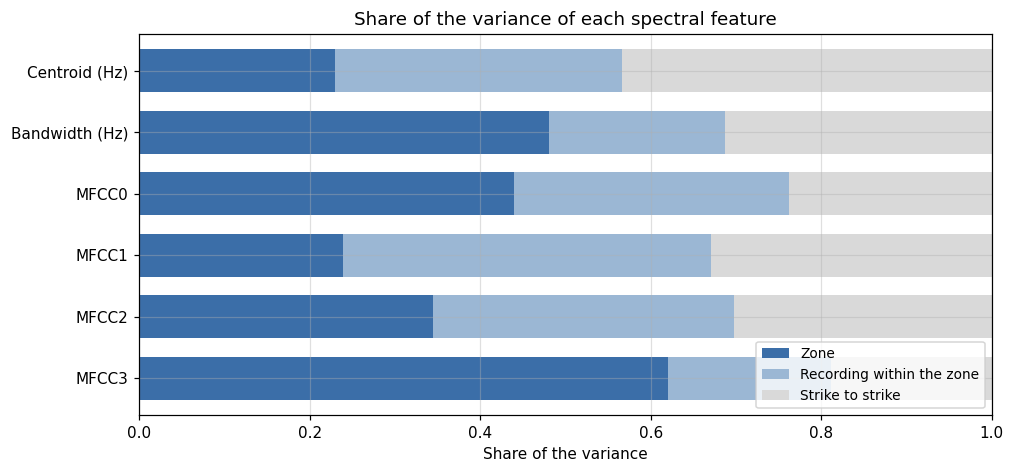

In [4]:
ax = vc.set_index("variable")[["zone", "recording", "strike"]].plot.barh(stacked=True, figsize=(10, 4.5),
        color=["#3b6ea8", "#9bb7d4", "#d9d9d9"], width=.7)
ax.set_xlabel("Share of the variance"); ax.set_ylabel(""); ax.set_xlim(0, 1)
ax.legend(["Zone", "Recording within the zone", "Strike to strike"], loc="lower right", fontsize=9)
ax.invert_yaxis(); ax.set_title("Share of the variance of each spectral feature")
plt.savefig(C.FIGURES / "fig05a_variance_components.png", dpi=150, bbox_inches="tight"); plt.show()

**Reading.** The zone is the largest source of variation for the bandwidth, MFCC0 and MFCC3. The **recording within
the zone** also contributes a large share, and for the centroid and MFCC1 more than the zone: the same point, recorded
in another file, sounds somewhat different (most probably because the hand-held microphone or the exact strike point
changed); this sets the repeatability of the protocol. The column `p_force` shows whether the strike force has a
detectable effect; its size is quantified in notebook 02.

## 5.3 Multivariate test: PERMANOVA

Considers the six features at once (standardised). The pseudo-F statistic compares the distances between strikes of
different zones with the distances within each zone; its p-value is obtained by permuting the zone labels 4999 times.

In [5]:
X = StandardScaler().fit_transform(d[list(VARS)])
D2 = squareform(pdist(X)) ** 2
def pseudo_F(g):
    n, labs = len(g), np.unique(g); a = len(labs)
    sst = D2.sum() / (2 * n)
    ssw = sum(D2[np.ix_(g == l, g == l)].sum() / (2 * (g == l).sum()) for l in labs)
    return ((sst - ssw) / (a - 1)) / (ssw / (n - a)), 1 - ssw / sst
g = d.zone.values
F0, R2 = pseudo_F(g)
perm = np.array([pseudo_F(rng.permutation(g))[0] for _ in range(4999)])
p = (np.sum(perm >= F0) + 1) / 5000
pd.DataFrame([{"pseudo_F": F0, "R2": R2, "p": p}]).to_csv(C.TABLES / "t05_permanova.csv", index=False)
print(f"PERMANOVA (6 features, 24 zones): pseudo-F = {F0:.1f}, R² = {R2:.2f}, p = {p:.4f}")

PERMANOVA (6 features, 24 zones): pseudo-F = 15.1, R² = 0.50, p = 0.0002


## Conclusion

* The 24 zones differ in all six features (Kruskal–Wallis) and jointly (PERMANOVA): see `t05_kruskal_wallis.csv` and
  `t05_permanova.csv`.
* **The zone is the main source of variation** for the bandwidth, MFCC0 and MFCC3; the recording within the zone and
  the strike-to-strike variation account for the rest, and the recording weighs as much as or more than the zone for
  the centroid, MFCC1 and MFCC2 (`t05_variance_components.csv`). The strike force enters as a covariate.